# Two-stage (Faster R-CNN) і one-stage anchor-based (RetinaNet), torchvision
Тюнінг Faster R-CNN (T1, T2): рани розкладаються по двох GPU паралельно. T0 і R0–R2 пораховані в попередній версії (4_draft, Version #4).
Kaggle: Input — дані змагання · GPU T4 ×2 · Internet On · Secret `WANDB_API_KEY`. Запуск: Save Version → Save & Run All.

Протокол: той самий датасет, що для YOLO/RT-DETR (кожен 4-й кадр train, ignore замальовано, val — кожен 2-й кадр),
довша сторона входу 1024 (min_size 576 / max_size 1024), ResNet-50-FPN v2 з COCO-ваг, SGD + cosine, AMP, seed 0.
Бюджет обмежений: **3 епохи** (YOLO вийшов на плато на 3-й епосі).

| Ран | Зміна | Навіщо |
|---|---|---|
| T0 | Faster R-CNN, дефолт: якорі 32–512, RPN 2000/1000 proposals, RoI 512 @ 25 % позитивів | бейслайн two-stage |
| T1 | якорі 8–128 + RPN 4000/2000 proposals | якорі з EDA §10 (дефолт покриває лише 23 % об'єктів); більше кандидатів для щільних сцен |
| T2 | T1 + RoI-семплінг 256 @ 50 % позитивів | більше позитивних прикладів для другої стадії |
| R0 | RetinaNet, дефолт: якорі 32–512 (×3 масштаби), GIoU loss | бейслайн one-stage anchor-based |
| R1 | якорі 8–128 (×3 масштаби) | якорі з EDA §10 |
| R2 | R1 + CIoU loss | модифікація лоссу: штраф за зсув центру і форму бокса |

## 1. Конфігурація і середовище

In [1]:
TV_RUNS = [
    # готово в 4_draft (Version #4): T0_frcnn_1024
    # dict(RUN_ID="T0_frcnn_1024", family="frcnn", CHANGE="baseline: anchors 32-512, RPN 2000/1000, RoI 512@0.25", lr=0.005),
    dict(RUN_ID="T1_frcnn_anch8_rpn4000_1024", family="frcnn", CHANGE="anchors 8-128 + RPN proposals 4000/2000",
         anchors=[8, 16, 32, 64, 128], rpn_pre=[4000, 2000], rpn_post=[4000, 2000], lr=0.005),
    dict(RUN_ID="T2_frcnn_roi256pos05_1024", family="frcnn", CHANGE="T1 + RoI sampling 256@0.5",
         anchors=[8, 16, 32, 64, 128], rpn_pre=[4000, 2000], rpn_post=[4000, 2000], roi_sampler=[256, 0.5], lr=0.005),
    # готово в 4_draft (Version #4): R0_retina_1024
    # dict(RUN_ID="R0_retina_1024", family="retina", CHANGE="baseline: anchors 32-512 (x3 scales), GIoU loss", lr=0.0025),
    # готово в 4_draft (Version #4): R1_retina_anch8_1024
    # dict(RUN_ID="R1_retina_anch8_1024", family="retina", CHANGE="anchors 8-128 (x3 scales)", anchors=[8, 16, 32, 64, 128], lr=0.0025),
    # готово в 4_draft (Version #4): R2_retina_anch8_ciou_1024
    # dict(RUN_ID="R2_retina_anch8_ciou_1024", family="retina", CHANGE="R1 + CIoU loss", anchors=[8, 16, 32, 64, 128], loss="ciou", lr=0.0025),
]
FAMILY_NAMES = {"frcnn": "two_stage", "retina": "one_stage_anchor"}
DEBUG = False                      # True: 2 кліпи, 48 кадрів train, 1 епоха — перевірка за ~10 хв

PROTOCOL = dict(train_step=4, val_step=2, train_max_side=1600, seed=0, conf=0.001, max_det=500,
                min_size=576, max_size=1024, epochs=3, batch=4, workers=3)
NAMES = ["person", "bicycle", "car", "van", "truck", "tricycle", "bus", "motor"]
WANDB_PROJECT = "hw2-ucu-2026"
WANDB_ENTITY  = "solchanykv-ukrainian-catholic-university"

import importlib.util, os, subprocess, sys
for pkg in ["pycocotools"]:
    if importlib.util.find_spec(pkg) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

import contextlib, copy, gc, io, json, pickle, random, shutil, time
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import torch
import torchvision


def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); os.environ["PYTHONHASHSEED"] = str(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)


def find_root():
    for pat in ["*", "*/*", "*/*/*"]:
        for c in Path("/kaggle/input").glob(pat):
            if (c / "train" / "annotations_coco.json").exists():
                return c
    raise FileNotFoundError("Додай дані змагання в Input")


def wandb_login():
    import wandb
    try:
        from kaggle_secrets import UserSecretsClient
        key = UserSecretsClient().get_secret("hw2")
    except Exception as e:
        print("W&B вимкнено:", e)
        return False
    os.environ.update(WANDB_API_KEY=key, WANDB_PROJECT=WANDB_PROJECT, WANDB_ENTITY=WANDB_ENTITY)
    return wandb.login(key=key, relogin=True)


seed_everything(PROTOCOL["seed"])
ROOT = find_root()
WORK = Path("/kaggle/working"); DS = WORK / "ds"; ART = WORK / "artifacts"; ART.mkdir(exist_ok=True)
MAX_CLIPS = 2 if DEBUG else None

assert torch.cuda.device_count() == 2, "Accelerator: GPU T4 x2"
USE_WANDB = wandb_login()
if DEBUG:
    PROTOCOL["epochs"] = 1
print("рани:", [r["RUN_ID"] for r in TV_RUNS], "| протокол:", PROTOCOL)
print(f"дані: {ROOT}\ntorchvision {torchvision.__version__} | torch {torch.__version__} | "
      f"GPU: {torch.cuda.get_device_name(0)} x{torch.cuda.device_count()} | W&B: {USE_WANDB}")

W&B вимкнено: Unexpected response from the service. Response: {'errors': ['No user secrets exist for kernel id 145411939 and label hw2.'], 'error': {'code': 5}, 'wasSuccessful': False}.
рани: ['T1_frcnn_anch8_rpn4000_1024', 'T2_frcnn_roi256pos05_1024'] | протокол: {'train_step': 4, 'val_step': 2, 'train_max_side': 1600, 'seed': 0, 'conf': 0.001, 'max_det': 500, 'min_size': 576, 'max_size': 1024, 'epochs': 3, 'batch': 4, 'workers': 3}
дані: /kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026
torchvision 0.26.0+cu130 | torch 2.11.0+cu130 | GPU: Tesla T4 x2 | W&B: False


## 2. Датасет за протоколом (той самий, що для YOLO і RT-DETR)

In [2]:
GRAY = 114


def frame_key(path):
    p = Path(path)
    return p.parent.name, p.stem


def read_yolo(path, W, H):
    p = Path(path)
    if not p.exists() or p.stat().st_size == 0:
        return np.zeros((0, 5))
    a = np.loadtxt(p, ndmin=2); out = a.copy()
    out[:, 1] = (a[:, 1] - a[:, 3] / 2) * W; out[:, 2] = (a[:, 2] - a[:, 4] / 2) * H
    out[:, 3] = a[:, 3] * W;                 out[:, 4] = a[:, 4] * H
    return out                                          # cls, x, y, w, h (px)


def read_ignore(path, W, H):
    p = Path(path)
    if not p.exists() or p.stat().st_size == 0:
        return np.zeros((0, 4))
    a = np.loadtxt(p, ndmin=2)[:, -4:]
    return np.c_[(a[:, 0] - a[:, 2] / 2) * W, (a[:, 1] - a[:, 3] / 2) * H, a[:, 2] * W, a[:, 3] * H]


def frac_inside(boxes, regions):
    if len(boxes) == 0 or len(regions) == 0:
        return np.zeros(len(boxes))
    a = np.c_[boxes[:, :2], boxes[:, :2] + boxes[:, 2:4]]
    b = np.c_[regions[:, :2], regions[:, :2] + regions[:, 2:4]]
    iw = np.clip(np.minimum(a[:, None, 2], b[None, :, 2]) - np.maximum(a[:, None, 0], b[None, :, 0]), 0, None)
    ih = np.clip(np.minimum(a[:, None, 3], b[None, :, 3]) - np.maximum(a[:, None, 1], b[None, :, 1]), 0, None)
    return (iw * ih / np.maximum(boxes[:, 2] * boxes[:, 3], 1e-9)[:, None]).max(1)


def list_frames(split, step=1, max_clips=None):
    clips = sorted(p for p in (ROOT / split / "images").iterdir() if p.is_dir())
    return [f for c in clips[:max_clips] for f in sorted(c.glob("*.jpg"))[::step]]


def _process(f, split, mask, max_side, drop_thr):
    clip, stem = f.parent.name, f.stem
    dst = DS / split / "images" / clip / f.name
    lbl = ROOT / split / "labels" / clip / f"{stem}.txt"
    ign = ROOT / split / "ignore" / clip / f"{stem}.txt"
    lines = lbl.read_text().strip().splitlines() if lbl.exists() else []
    n_drop = 0
    need_mask = mask and ign.exists() and ign.stat().st_size > 0
    if need_mask or max_side:
        img = cv2.imread(str(f)); H, W = img.shape[:2]
        if need_mask:
            reg = read_ignore(ign, W, H)
            for x, y, w, h in reg:
                img[max(0, int(y)):int(np.ceil(y + h)), max(0, int(x)):int(np.ceil(x + w))] = GRAY
            if lines:
                keep = frac_inside(read_yolo(lbl, W, H)[:, 1:], reg) <= drop_thr
                n_drop = int((~keep).sum()); lines = [l for l, k in zip(lines, keep) if k]
        if max_side and max(H, W) > max_side:
            s = max_side / max(H, W)
            img = cv2.resize(img, (round(W * s), round(H * s)), interpolation=cv2.INTER_AREA)
        cv2.imwrite(str(dst), img, [cv2.IMWRITE_JPEG_QUALITY, 95])
    elif not dst.exists():
        dst.symlink_to(f)
    (DS / split / "labels" / clip / f"{stem}.txt").write_text("\n".join(lines) + ("\n" if lines else ""))
    return n_drop


def build_split(split, step, mask=False, max_side=None, drop_thr=0.5, max_clips=None):
    frames = list_frames(split, step, max_clips)
    for clip in {f.parent.name for f in frames}:
        (DS / split / "images" / clip).mkdir(parents=True, exist_ok=True)
        (DS / split / "labels" / clip).mkdir(parents=True, exist_ok=True)
    with ThreadPoolExecutor(8) as ex:
        drops = list(ex.map(lambda f: _process(f, split, mask, max_side, drop_thr), frames))
    print(f"{split}: {len(frames)} кадрів, видалено GT під ignore: {sum(drops)}")


if not (DS / "data.yaml").exists():
    t0 = time.time()
    build_split("train", PROTOCOL["train_step"], mask=True, max_side=PROTOCOL["train_max_side"], max_clips=MAX_CLIPS)
    build_split("val", PROTOCOL["val_step"], mask=False, max_clips=MAX_CLIPS)
    (DS / "data.yaml").write_text(f"path: {DS}\ntrain: train/images\nval: val/images\nnames:\n"
                                  + "".join(f"  {i}: {n}\n" for i, n in enumerate(NAMES)))
    print(f"зібрано за {time.time() - t0:.0f} с")

VAL = list_frames("val", PROTOCOL["val_step"], MAX_CLIPS)
test_df = pd.read_csv(ROOT / "test_images.csv")
TEST = [ROOT / f for f in test_df.file_name]
if DEBUG:
    VAL, TEST = VAL[:50], TEST[:50]
print(f"val: {len(VAL)} | test: {len(TEST)}")

train: 6072 кадрів, видалено GT під ignore: 3069
val: 1425 кадрів, видалено GT під ignore: 0
зібрано за 116 с
val: 1425 | test: 3811


## 3. Скрипт тренування torchvision-моделей
Дані → модель (заміна голови на 8 класів, якорі/RPN/RoI за конфігом) → SGD+cosine, AMP → val-метрики, FPS, recall RPN vs фінальних детекцій → W&B → сабміт.

In [3]:
%%writefile /kaggle/working/tv_train.py
# Torchvision detectors (Faster R-CNN v2, RetinaNet v2): train -> val metrics -> W&B -> test submission -> artifacts.
# One process = one GPU = one family; the notebook starts two processes in parallel.
import argparse, contextlib, gc, io, json, math, os, pickle, time
from functools import partial
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from torch.utils.data import DataLoader, Dataset
from torchvision.models.detection import fasterrcnn_resnet50_fpn_v2, retinanet_resnet50_fpn_v2
from torchvision.models.detection._utils import BalancedPositiveNegativeSampler
from torchvision.models.detection.anchor_utils import AnchorGenerator
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.retinanet import RetinaNetClassificationHead
from torchvision.ops import box_iou

ap = argparse.ArgumentParser()
ap.add_argument("--cfg", required=True)
C = json.loads(Path(ap.parse_args().cfg).read_text())
ROOT, DS, ART = Path(C["root"]), Path(C["ds"]), Path(C["art"])
NAMES, P, DEBUG = C["names"], C["protocol"], C["debug"]
DEV = torch.device("cuda")
torch.manual_seed(P["seed"]); np.random.seed(P["seed"])
torch.backends.cudnn.benchmark = True


def log(*a):
    print(time.strftime("%H:%M:%S"), *a, flush=True)


def frame_key(path):
    p = Path(path)
    return p.parent.name, p.stem


def list_frames(root, split, step=1, max_clips=None):
    clips = sorted(p for p in (Path(root) / split / "images").iterdir() if p.is_dir())
    return [f for c in clips[:max_clips] for f in sorted(c.glob("*.jpg"))[::step]]


def read_rgb(p):
    return cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)


# ---------------- data ----------------
class TrainSet(Dataset):
    """Frames of the prepared dataset (ignore painted gray, GT under masks removed). Augmentation: horizontal flip."""

    def __init__(self, paths):
        self.paths = paths

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        p = self.paths[i]
        img = read_rgb(p); H, W = img.shape[:2]
        lbl = DS / "train" / "labels" / p.parent.name / f"{p.stem}.txt"
        a = np.loadtxt(lbl, ndmin=2) if lbl.exists() and lbl.stat().st_size else np.zeros((0, 5))
        boxes = np.stack([(a[:, 1] - a[:, 3] / 2) * W, (a[:, 2] - a[:, 4] / 2) * H,
                          (a[:, 1] + a[:, 3] / 2) * W, (a[:, 2] + a[:, 4] / 2) * H], 1).astype(np.float32)
        labels = a[:, 0].astype(np.int64) + 1                       # 0 = background in torchvision
        keep = ((boxes[:, 2] - boxes[:, 0]) >= 1) & ((boxes[:, 3] - boxes[:, 1]) >= 1)
        boxes, labels = boxes[keep], labels[keep]
        if torch.rand(1).item() < 0.5:
            img = img[:, ::-1].copy()
            boxes[:, [0, 2]] = W - boxes[:, [2, 0]]
        t = torch.from_numpy(img).permute(2, 0, 1).float().div_(255)
        return t, {"boxes": torch.from_numpy(boxes).reshape(-1, 4), "labels": torch.from_numpy(labels)}


def collate(b):
    return tuple(zip(*b))


# ---------------- evaluation (same as the Ultralytics notebooks) ----------------
class Evaluator:
    def __init__(self, gt_json, image_paths):
        with contextlib.redirect_stdout(io.StringIO()):
            self.gt = COCO(str(gt_json))
        self.key2id = {frame_key(i["file_name"]): i["id"] for i in self.gt.dataset["images"]}
        self.img_ids = [self.key2id[frame_key(p)] for p in image_paths]

    def evaluate(self, preds):
        dets = []
        for k, (xyxy, s, c) in preds.items():
            for i in np.argsort(-np.asarray(s, np.float32))[:P["max_det"]]:
                x1, y1, x2, y2 = map(float, xyxy[i])
                dets.append(dict(image_id=self.key2id[k], category_id=int(c[i]) + 1,
                                 bbox=[x1, y1, x2 - x1, y2 - y1], score=float(s[i])))
        if not dets:
            return dict(mAP=0.0)
        with contextlib.redirect_stdout(io.StringIO()):
            E = COCOeval(self.gt, self.gt.loadRes(dets), "bbox")
            E.params.imgIds = self.img_ids
            E.params.maxDets = [1, 100, P["max_det"]]
            E.evaluate(); E.accumulate(); E.summarize()
        s, prec = E.stats, E.eval["precision"]
        p_all = prec[:, :, :, 0, -1]
        m = dict(mAP=p_all[p_all > -1].mean(), AP50=s[1], AP75=s[2], AP_small=s[3], AP_medium=s[4],
                 AP_large=s[5], AR500=s[8])
        for k, n in enumerate(NAMES):
            p = prec[:, :, k, 0, -1]
            m[f"AP_{n}"] = p[p > -1].mean() if (p > -1).any() else np.nan
        return {k: float(v) for k, v in m.items()}


# ---------------- models ----------------
def build(cfg):
    nc = len(NAMES) + 1
    if cfg["family"] == "frcnn":
        m = fasterrcnn_resnet50_fpn_v2(weights="DEFAULT", min_size=P["min_size"], max_size=P["max_size"],
                                       box_detections_per_img=P["max_det"], box_score_thresh=P["conf"])
        m.roi_heads.box_predictor = FastRCNNPredictor(m.roi_heads.box_predictor.cls_score.in_features, nc)
        if cfg.get("anchors"):
            m.rpn.anchor_generator = AnchorGenerator(tuple((s,) for s in cfg["anchors"]),
                                                     ((0.5, 1.0, 2.0),) * len(cfg["anchors"]))
        if cfg.get("rpn_pre"):
            m.rpn._pre_nms_top_n = dict(training=cfg["rpn_pre"][0], testing=cfg["rpn_pre"][1])
            m.rpn._post_nms_top_n = dict(training=cfg["rpn_post"][0], testing=cfg["rpn_post"][1])
        if cfg.get("roi_sampler"):
            m.roi_heads.fg_bg_sampler = BalancedPositiveNegativeSampler(*cfg["roi_sampler"])
    else:
        m = retinanet_resnet50_fpn_v2(weights="DEFAULT", min_size=P["min_size"], max_size=P["max_size"],
                                      detections_per_img=P["max_det"], score_thresh=P["conf"], topk_candidates=1000)
        na = m.head.classification_head.num_anchors
        m.head.classification_head = RetinaNetClassificationHead(256, na, nc, norm_layer=partial(nn.GroupNorm, 32))
        if cfg.get("anchors"):
            sizes = tuple(tuple(int(round(s * 2 ** (i / 3))) for i in range(3)) for s in cfg["anchors"])
            m.anchor_generator = AnchorGenerator(sizes, ((0.5, 1.0, 2.0),) * len(sizes))
        if cfg.get("loss"):
            m.head.regression_head._loss_type = cfg["loss"]
    return m.to(DEV)


def describe(m, cfg):
    if cfg["family"] == "frcnn":
        return dict(model_anchor_sizes=[s[0] for s in m.rpn.anchor_generator.sizes], model_rpn_pre=m.rpn._pre_nms_top_n,
                    model_rpn_post=m.rpn._post_nms_top_n, model_roi_batch=m.roi_heads.fg_bg_sampler.batch_size_per_image,
                    model_roi_pos=m.roi_heads.fg_bg_sampler.positive_fraction)
    return dict(model_anchor_sizes=[list(s) for s in m.anchor_generator.sizes], model_box_loss=m.head.regression_head._loss_type)


# ---------------- train / predict ----------------
def train(m, cfg, run):
    paths = list_frames(DS, "train")
    if DEBUG:
        paths = paths[:48]
    dl = DataLoader(TrainSet(paths), batch_size=P["batch"], shuffle=True, num_workers=P["workers"],
                    collate_fn=collate, drop_last=True, persistent_workers=True, pin_memory=True)
    params = [p for p in m.parameters() if p.requires_grad]
    opt = torch.optim.SGD(params, lr=cfg["lr"], momentum=0.9, weight_decay=1e-4)
    total = P["epochs"] * len(dl)
    warm = max(1, min(300, total // 5))
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda it: (it + 1) / warm if it < warm else 0.5 * (1 + math.cos(math.pi * (it - warm) / max(1, total - warm))))
    scaler = torch.amp.GradScaler("cuda")
    m.train(); it = 0; t0 = time.time()
    for ep in range(P["epochs"]):
        run_loss = 0.0
        for imgs, tgts in dl:
            imgs = [i.to(DEV, non_blocking=True) for i in imgs]
            tgts = [{k: v.to(DEV) for k, v in t.items()} for t in tgts]
            with torch.autocast("cuda", dtype=torch.float16):
                losses = m(imgs, tgts)
            loss = sum(losses.values())
            opt.zero_grad(set_to_none=True)
            if not torch.isfinite(loss):
                continue
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(params, 10.0)
            scaler.step(opt); scaler.update(); sched.step(); it += 1
            run_loss += loss.item()
            if it % 50 == 0:
                if run is not None:
                    run.log({"train/loss": loss.item(), **{f"train/{k}": v.item() for k, v in losses.items()},
                             "lr": opt.param_groups[0]["lr"], "epoch": it / len(dl)}, step=it)
            if it % 500 == 0:
                log(f"{cfg['RUN_ID']} ep {ep + 1} it {it}/{total} loss {loss.item():.3f} ({(time.time() - t0) / 60:.0f} хв)")
        log(f"{cfg['RUN_ID']} епоха {ep + 1}: середній loss {run_loss / max(1, len(dl)):.3f}")
    return (time.time() - t0) / 60


@torch.no_grad()
def predict(m, paths, bs=4):
    m.eval(); out = {}
    for i in range(0, len(paths), bs):
        chunk = paths[i:i + bs]
        imgs = [torch.from_numpy(read_rgb(p)).permute(2, 0, 1).float().div_(255).to(DEV) for p in chunk]
        with torch.autocast("cuda", dtype=torch.float16):
            res = m(imgs)
        for p, r in zip(chunk, res):
            b = r["boxes"].float().cpu().numpy(); s = r["scores"].float().cpu().numpy(); l = r["labels"].cpu().numpy()
            k = l > 0
            out[frame_key(p)] = (b[k].astype(np.float32), s[k].astype(np.float32), (l[k] - 1).astype(np.int8))
        del imgs, res
    return out


@torch.no_grad()
def measure_fps(m, paths, n=60, warmup=5):
    m.eval(); paths = paths[: n + warmup]
    imgs = [torch.from_numpy(read_rgb(p)).permute(2, 0, 1).float().div_(255).to(DEV) for p in paths]
    for x in imgs[:warmup]:
        with torch.autocast("cuda", dtype=torch.float16):
            m([x])
    torch.cuda.synchronize(); t = time.perf_counter()
    for x in imgs[warmup:]:
        with torch.autocast("cuda", dtype=torch.float16):
            m([x])
    torch.cuda.synchronize()
    ms = (time.perf_counter() - t) / max(1, len(imgs) - warmup) * 1000
    del imgs
    return dict(ms_per_img=ms, FPS=1000 / ms)


@torch.no_grad()
def rpn_vs_final_recall(m, ev, paths, n=150):
    """What each stage contributes: recall of RPN proposals vs recall of the final (second-stage) detections."""
    m.eval(); res = dict(gt=0, rpn50=0, rpn70=0, det50=0, det50_conf03=0, n_props=0)
    step = max(1, len(paths) // n)
    for p in paths[::step][:n]:
        anns = [a for a in ev.gt.imgToAnns[ev.key2id[frame_key(p)]] if not a.get("iscrowd", 0)]
        if not anns:
            continue
        g = torch.tensor([[a["bbox"][0], a["bbox"][1], a["bbox"][0] + a["bbox"][2], a["bbox"][1] + a["bbox"][3]]
                          for a in anns], dtype=torch.float32, device=DEV)
        img = torch.from_numpy(read_rgb(p)).permute(2, 0, 1).float().div_(255).to(DEV)
        H, W = img.shape[1:]
        il, _ = m.transform([img])
        feats = m.backbone(il.tensors)
        props, _ = m.rpn(il, feats)
        h, w = il.image_sizes[0]
        props = props[0] * torch.tensor([W / w, H / h, W / w, H / h], device=DEV)
        iou = box_iou(g, props).max(1).values
        det = m([img])[0]
        d_iou = box_iou(g, det["boxes"]).max(1).values if len(det["boxes"]) else torch.zeros(len(g), device=DEV)
        hi = det["scores"] >= 0.3
        d_iou3 = box_iou(g, det["boxes"][hi]).max(1).values if hi.any() else torch.zeros(len(g), device=DEV)
        res["gt"] += len(g); res["n_props"] += len(props)
        res["rpn50"] += int((iou >= 0.5).sum()); res["rpn70"] += int((iou >= 0.7).sum())
        res["det50"] += int((d_iou >= 0.5).sum()); res["det50_conf03"] += int((d_iou3 >= 0.5).sum())
    g = max(1, res["gt"])
    return dict(rpn_recall50=res["rpn50"] / g, rpn_recall70=res["rpn70"] / g, det_recall50=res["det50"] / g,
                det_recall50_conf03=res["det50_conf03"] / g, proposals_per_img=res["n_props"] / max(1, n))


def write_submission(preds, test_df, path):
    rows = []
    for iid, fn in zip(test_df.image_id, test_df.file_name):
        xyxy, s, c = preds.get(frame_key(fn), (np.zeros((0, 4)), np.zeros(0), np.zeros(0)))
        w, h = xyxy[:, 2] - xyxy[:, 0], xyxy[:, 3] - xyxy[:, 1]
        keep = np.where((w >= 1) & (h >= 1))[0]
        o = keep[np.argsort(-s[keep])][:P["max_det"]]
        rows.append((iid, " ".join(f"{int(c[i])} {s[i]:.4f} {xyxy[i, 0]:.1f} {xyxy[i, 1]:.1f} {w[i]:.1f} {h[i]:.1f}" for i in o)))
    pd.DataFrame(rows, columns=["image_id", "PredictionString"]).to_csv(path, index=False)


def boxes_image(path, pred, conf=0.3, max_side=1280):
    import wandb
    img = read_rgb(path); H, W = img.shape[:2]
    s = min(1.0, max_side / max(H, W))
    if s < 1:
        img = cv2.resize(img, (round(W * s), round(H * s)), interpolation=cv2.INTER_AREA)
    clip, stem = frame_key(path)
    lbl = ROOT / "val" / "labels" / clip / f"{stem}.txt"
    a = np.loadtxt(lbl, ndmin=2) if lbl.exists() and lbl.stat().st_size else np.zeros((0, 5))
    cl = dict(enumerate(NAMES))
    box = lambda x1, y1, x2, y2: {"minX": float(x1) * s, "minY": float(y1) * s, "maxX": float(x2) * s, "maxY": float(y2) * s}
    xyxy, sc, c = pred
    keep = sc >= conf
    return wandb.Image(img, caption=f"{clip}/{stem}", boxes={
        "ground_truth": {"class_labels": cl, "box_data": [
            {"position": box((cx - bw / 2) * W, (cy - bh / 2) * H, (cx + bw / 2) * W, (cy + bh / 2) * H),
             "domain": "pixel", "class_id": int(k)} for k, cx, cy, bw, bh in a]},
        "predictions": {"class_labels": cl, "box_data": [
            {"position": box(*b), "domain": "pixel", "class_id": int(k), "scores": {"conf": float(v)}}
            for b, v, k in zip(xyxy[keep], sc[keep], c[keep])]}})


# ---------------- main ----------------
VAL = list_frames(ROOT, "val", P["val_step"], 2 if DEBUG else None)
test_df = pd.read_csv(ROOT / "test_images.csv")
TEST = [ROOT / f for f in test_df.file_name]
if DEBUG:
    VAL, TEST = VAL[:50], TEST[:50]
ev = Evaluator(ROOT / "val" / "annotations_coco.json", VAL)
use_wandb = bool(os.environ.get("WANDB_API_KEY"))

for cfg in C["runs"]:
    run_id = cfg["RUN_ID"]; out = ART / run_id; out.mkdir(parents=True, exist_ok=True)
    run = None
    try:
        log(f"===== {run_id}: {cfg['CHANGE']} =====")
        m = build(cfg)
        if use_wandb:
            import wandb
            run = wandb.init(project=C["wandb_project"], entity=C["wandb_entity"], name=run_id, group=C["family_names"][cfg["family"]],
                             config=dict(P, **cfg, **describe(m, cfg), debug=DEBUG))
        train_min = train(m, cfg, run)
        torch.save(m.state_dict(), out / "weights.pt")

        val_preds = predict(m, VAL)
        metrics = ev.evaluate(val_preds)
        metrics.update(measure_fps(m, VAL))
        metrics["train_min"] = train_min
        if cfg["family"] == "frcnn":
            metrics.update(rpn_vs_final_recall(m, ev, VAL))
        log(f"{run_id}: " + ", ".join(f"{k} {v:.4f}" for k, v in metrics.items() if not k.startswith("AP_") or k in ("AP_small",)))

        if run is not None:
            run.summary.update(metrics)
            idx = np.linspace(0, len(VAL) - 1, 12).astype(int)
            run.log({"val_predictions": [boxes_image(VAL[i], val_preds[frame_key(VAL[i])]) for i in idx]})
            run.finish()

        test_preds = predict(m, TEST)
        write_submission(test_preds, test_df, out / f"submission_{run_id}.csv")
        for tag, p in [("val", val_preds), ("test", test_preds)]:
            pickle.dump({k: (b, s.astype(np.float16), c) for k, (b, s, c) in p.items()}, open(out / f"{tag}_preds.pkl", "wb"))
        json.dump(dict(run_id=run_id, **cfg, **describe(m, cfg), protocol=P, debug=DEBUG, **metrics),
                  open(out / "metrics.json", "w"), indent=1, default=str)
        log(f"{run_id}: готово")
    except Exception:
        import traceback
        log(f"!!! {run_id} впав"); traceback.print_exc()
        if run is not None:
            run.finish(exit_code=1)
    finally:
        for v in ["m", "val_preds", "test_preds"]:
            globals().pop(v, None)
        gc.collect(); torch.cuda.empty_cache()


Writing /kaggle/working/tv_train.py


## 4. Запуск: Faster R-CNN на GPU 0, RetinaNet на GPU 1 — паралельно
Повні логи: `artifacts/tv_frcnn.log`, `artifacts/tv_retina.log`; тут — останній рядок кожного логу раз на 10 хв.

In [4]:
procs = {}
active = [r for r in TV_RUNS]
for gpu in (0, 1):                                   # рани розкладаються по двох GPU почергово
    fam = f"gpu{gpu}"
    cfg_path = WORK / f"tv_{fam}.json"
    cfg_path.write_text(json.dumps(dict(root=str(ROOT), ds=str(DS), art=str(ART), names=NAMES, protocol=PROTOCOL,
                                        debug=DEBUG, wandb_project=WANDB_PROJECT, wandb_entity=WANDB_ENTITY,
                                        family_names=FAMILY_NAMES, runs=active[gpu::2])))
    log_f = open(ART / f"tv_{fam}.log", "w")
    env = dict(os.environ, CUDA_VISIBLE_DEVICES=str(gpu), PYTHONUNBUFFERED="1")
    procs[fam] = (subprocess.Popen([sys.executable, str(WORK / "tv_train.py"), "--cfg", str(cfg_path)],
                                   stdout=log_f, stderr=subprocess.STDOUT, env=env), log_f)

t0 = time.time()
while any(p.poll() is None for p, _ in procs.values()):
    time.sleep(600 if not DEBUG else 60)
    for fam in procs:
        lines = (ART / f"tv_{fam}.log").read_text().strip().splitlines()
        print(f"[{(time.time() - t0) / 60:.0f} хв] {fam}: {lines[-1] if lines else '...'}")
for fam, (p, f) in procs.items():
    f.close()
    print(fam, "код виходу", p.returncode)
    errs = [l for l in (ART / f"tv_{fam}.log").read_text().splitlines() if "впав" in l or "Error" in l]
    if errs:
        print("\n".join(errs[-10:]))

[10 хв] gpu0: 14:25:26 T1_frcnn_anch8_rpn4000_1024 ep 1 it 1000/4554 loss 0.563 (9 хв)
[10 хв] gpu1: 14:24:25 T2_frcnn_roi256pos05_1024 ep 1 it 1000/4554 loss 0.981 (8 хв)
[20 хв] gpu0: 14:33:57 T1_frcnn_anch8_rpn4000_1024 ep 2 it 2000/4554 loss 0.747 (17 хв)
[20 хв] gpu1: 14:35:35 T2_frcnn_roi256pos05_1024 ep 2 it 2500/4554 loss 1.080 (19 хв)
[30 хв] gpu0: 14:42:45 T1_frcnn_anch8_rpn4000_1024 епоха 2: середній loss 0.609
[30 хв] gpu1: 14:43:01 T2_frcnn_roi256pos05_1024 ep 3 it 3500/4554 loss 1.011 (26 хв)
[40 хв] gpu0: 14:55:37 T1_frcnn_anch8_rpn4000_1024 епоха 3: середній loss 0.553
[40 хв] gpu1: 14:50:51 T2_frcnn_roi256pos05_1024 епоха 3: середній loss 0.878
[50 хв] gpu0: 15:03:01 T1_frcnn_anch8_rpn4000_1024: mAP 0.1889, AP50 0.3993, AP75 0.1557, AP_small 0.0858, AR500 0.4153, ms_per_img 72.4677, FPS 13.7992, train_min 38.8326, rpn_recall50 0.8907, rpn_recall70 0.5355, det_recall50 0.8294, det_recall50_conf03 0.7314, proposals_per_img 2000.0000
[50 хв] gpu1: 15:05:06 T2_frcnn_roi256

## 5. Підсумок: метрики, recall RPN vs фінальних детекцій, рядки для `experiments.csv`

In [5]:
res = {r["RUN_ID"]: json.load(open(ART / r["RUN_ID"] / "metrics.json")) for r in TV_RUNS
       if (ART / r["RUN_ID"] / "metrics.json").exists()}
main = ["mAP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large", "AR500", "FPS", "train_min"]
display(pd.DataFrame({k: {m: v[m] for m in main} for k, v in res.items()}).T.round(4))
display(pd.DataFrame({k: {n: v[f"AP_{n}"] for n in NAMES} for k, v in res.items()}).T.round(4))
rpn = {k: {m: v[m] for m in ["rpn_recall50", "rpn_recall70", "det_recall50", "det_recall50_conf03", "proposals_per_img"]}
       for k, v in res.items() if "rpn_recall50" in v}
if rpn:
    display(pd.DataFrame(rpn).T.round(3))

print("\nрядки для code/results/experiments.csv:")
for k, v in res.items():
    cfg = next(r for r in TV_RUNS if r["RUN_ID"] == k)
    model = "fasterrcnn_r50_fpn_v2" if cfg["family"] == "frcnn" else "retinanet_r50_fpn_v2"
    print(",".join(map(str, [k, FAMILY_NAMES[cfg["family"]], model, cfg["CHANGE"].replace(",", ";"), 1024, PROTOCOL["epochs"]]
                       + [f"{v[m]:.4f}" for m in ["mAP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large"]]
                       + [f"{v['FPS']:.1f}", "", k, "DEBUG" if DEBUG else ""])))

,mAP,AP50,AP75,AP_small,AP_medium,AP_large,AR500,FPS,train_min
T1_frcnn_anch8_rpn4000_1024,0.1889,0.3993,0.1557,0.0858,0.1781,0.3535,0.4153,13.7992,38.8326
T2_frcnn_roi256pos05_1024,0.1858,0.3947,0.1504,0.0843,0.1732,0.3559,0.3716,13.6131,34.0725


,person,bicycle,car,van,truck,tricycle,bus,motor
T1_frcnn_anch8_rpn4000_1024,0.2517,0.1864,0.3717,0.2112,0.158,0.1785,0.0517,0.1018
T2_frcnn_roi256pos05_1024,0.2518,0.1713,0.3676,0.1925,0.204,0.1871,0.0152,0.0972


,rpn_recall50,rpn_recall70,det_recall50,det_recall50_conf03,proposals_per_img
T1_frcnn_anch8_rpn4000_1024,0.891,0.535,0.829,0.731,2000.0
T2_frcnn_roi256pos05_1024,0.884,0.543,0.834,0.752,2000.0



рядки для code/results/experiments.csv:
T1_frcnn_anch8_rpn4000_1024,two_stage,fasterrcnn_r50_fpn_v2,anchors 8-128 + RPN proposals 4000/2000,1024,3,0.1889,0.3993,0.1557,0.0858,0.1781,0.3535,13.8,,T1_frcnn_anch8_rpn4000_1024,
T2_frcnn_roi256pos05_1024,two_stage,fasterrcnn_r50_fpn_v2,T1 + RoI sampling 256@0.5,1024,3,0.1858,0.3947,0.1504,0.0843,0.1732,0.3559,13.6,,T2_frcnn_roi256pos05_1024,


## 6. Аналіз помилок (найкращий Faster R-CNN і найкращий RetinaNet)
Кожна детекція з впевненістю ≥ 0.3 (поза ignore-зонами) потрапляє в одну категорію: **TP** (IoU ≥ 0.5, той самий клас),
**клас** (IoU ≥ 0.5, інший клас), **дублікат** (GT уже знайдено), **локалізація** (0.1 ≤ IoU < 0.5, той самий клас),
**фон** (IoU < 0.1). GT без пари — **пропуск**, з розбивкою за розміром. Три кадри-приклади: найбільше пропущених дрібних,
найбільше плутанини класів, найбільше хибних детекцій на фоні.


T1_frcnn_anch8_rpn4000_1024: детекцій (conf≥0.3) 77984, GT 57178
найчастіша плутанина (GT → предикт): [(('van', 'car'), 1710), (('bicycle', 'motor'), 1591), (('motor', 'person'), 1233), (('person', 'motor'), 551), (('tricycle', 'car'), 485)]


,tp,cls,dup,loc,bg
частка детекцій,0.461,0.115,0.015,0.099,0.311


,miss_small,miss_med,miss_large
частка GT,0.101,0.247,0.024


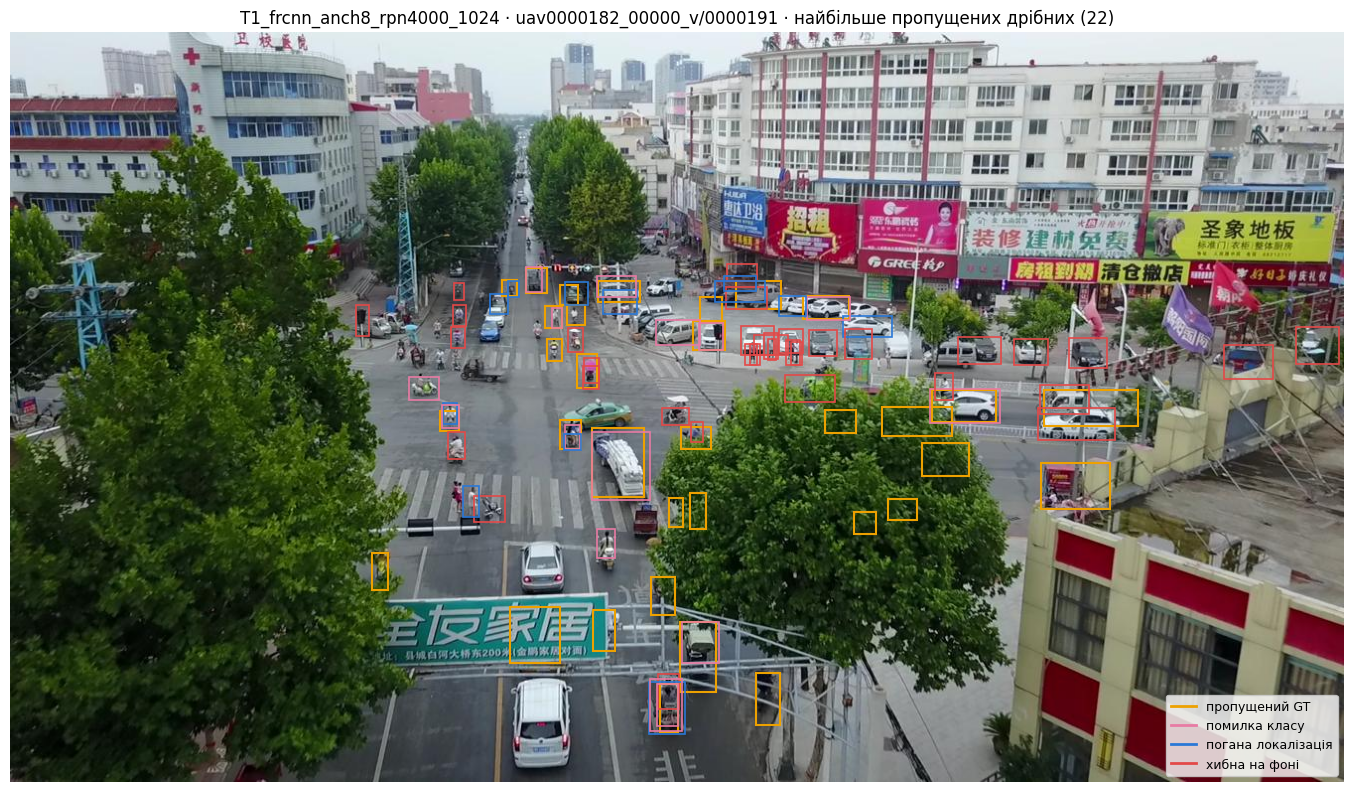

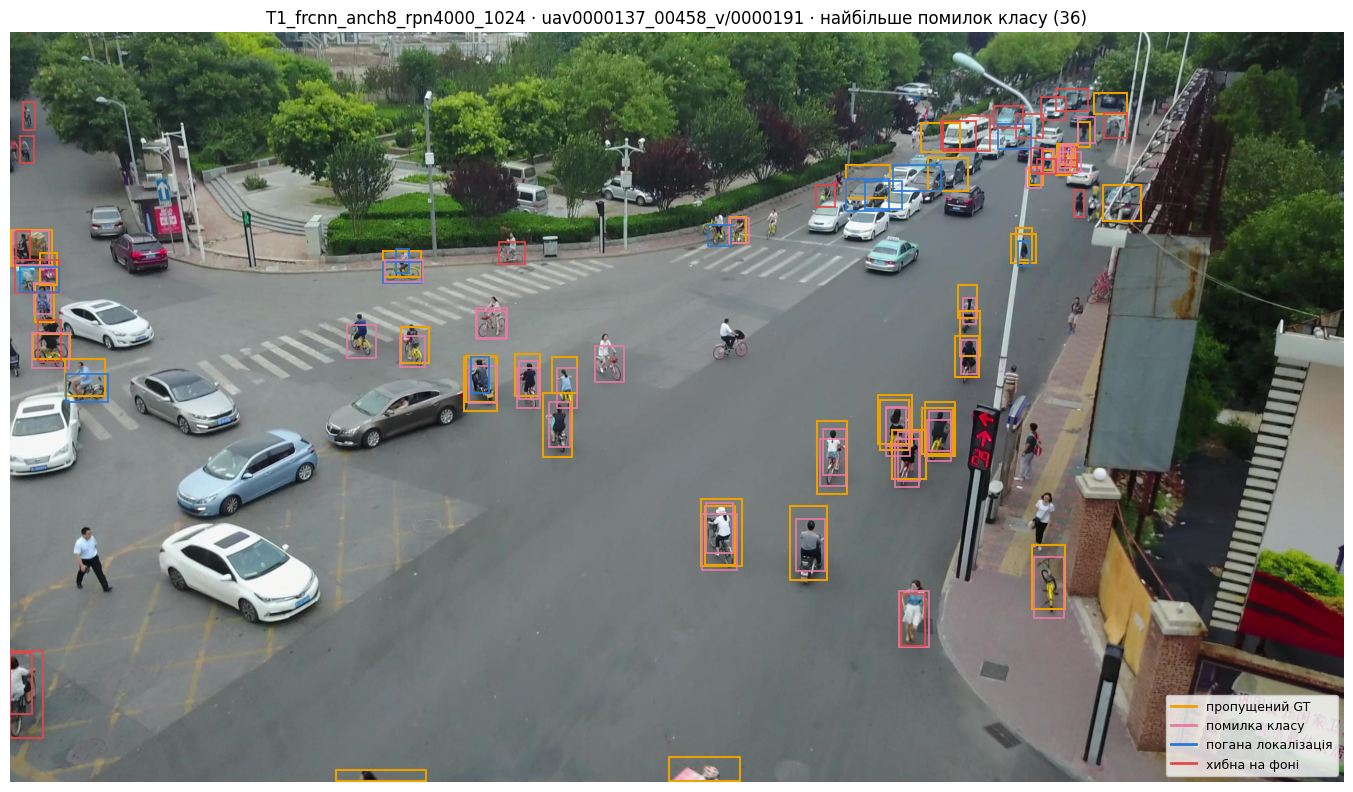

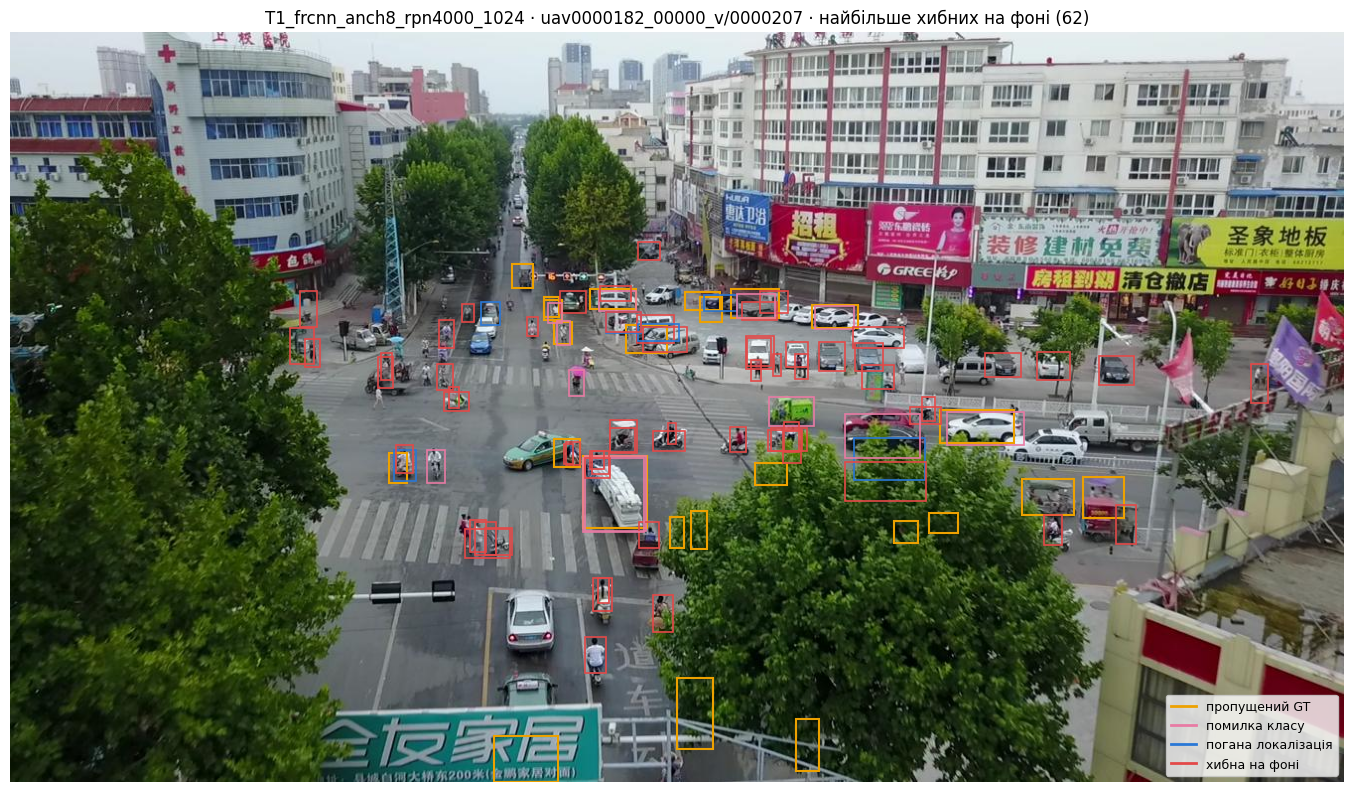

In [6]:
import matplotlib.pyplot as plt
from pycocotools.coco import COCO

with contextlib.redirect_stdout(io.StringIO()):
    GT = COCO(str(ROOT / "val" / "annotations_coco.json"))
KEY2ID = {frame_key(i["file_name"]): i["id"] for i in GT.dataset["images"]}
COLORS = {"tp": "#1baf7a", "miss": "#eda100", "cls": "#e87ba4", "loc": "#2a78d6", "bg": "#e34948"}


def iou_np(a, b):
    ix = np.clip(np.minimum(a[:, None, 2], b[None, :, 2]) - np.maximum(a[:, None, 0], b[None, :, 0]), 0, None)
    iy = np.clip(np.minimum(a[:, None, 3], b[None, :, 3]) - np.maximum(a[:, None, 1], b[None, :, 1]), 0, None)
    inter = ix * iy
    aa = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1]); ab = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / (aa[:, None] + ab[None, :] - inter + 1e-9)


def analyse(run_id, conf=0.3):
    preds = pickle.load(open(ART / run_id / "val_preds.pkl", "rb"))
    tot = dict(tp=0, cls=0, dup=0, loc=0, bg=0, miss_small=0, miss_med=0, miss_large=0, gt=0)
    frames, confusion = [], {}
    for k, (b, s, c) in preds.items():
        anns = GT.imgToAnns[KEY2ID[k]]
        g = np.array([[a["bbox"][0], a["bbox"][1], a["bbox"][0] + a["bbox"][2], a["bbox"][1] + a["bbox"][3]]
                      for a in anns if not a["iscrowd"]]).reshape(-1, 4)
        gc_ = np.array([a["category_id"] - 1 for a in anns if not a["iscrowd"]])
        ign = np.unique(np.array([a["bbox"] for a in anns if a["iscrowd"]]).reshape(-1, 4), axis=0)
        b, s, c = np.asarray(b, np.float32), np.asarray(s, np.float32), np.asarray(c)
        keep = s >= conf
        b, s, c = b[keep], s[keep], c[keep]
        if len(ign) and len(b):
            inside = frac_inside(np.c_[b[:, :2], b[:, 2:] - b[:, :2]], ign)
            b, s, c = b[inside <= 0.5], s[inside <= 0.5], c[inside <= 0.5]
        order = np.argsort(-s); b, c = b[order], c[order]
        m = iou_np(b, g) if len(b) and len(g) else np.zeros((len(b), len(g)))
        matched = np.zeros(len(g), bool); kinds = []
        for i in range(len(b)):
            j = int(m[i].argmax()) if len(g) else -1
            v = m[i, j] if j >= 0 else 0.0
            if v >= 0.5 and c[i] == gc_[j]:
                kind = "dup" if matched[j] else "tp"; matched[j] = True
            elif v >= 0.5:
                kind = "cls"; pair = (NAMES[gc_[j]], NAMES[c[i]]); confusion[pair] = confusion.get(pair, 0) + 1
            elif v >= 0.1 and c[i] == gc_[j]:
                kind = "loc"
            else:
                kind = "bg"
            kinds.append(kind); tot[kind] += 1
        side = np.sqrt((g[:, 2] - g[:, 0]) * (g[:, 3] - g[:, 1])) if len(g) else np.zeros(0)
        miss = ~matched
        tot["miss_small"] += int((miss & (side < 32)).sum()); tot["miss_med"] += int((miss & (side >= 32) & (side < 96)).sum())
        tot["miss_large"] += int((miss & (side >= 96)).sum()); tot["gt"] += len(g)
        frames.append(dict(key=k, b=b, kinds=kinds, g=g, miss=miss, miss_small=int((miss & (side < 32)).sum()),
                           n_cls=kinds.count("cls"), n_bg=kinds.count("bg")))
    return tot, frames, confusion


def draw_case(run_id, f, title, fname):
    clip, stem = f["key"]
    img = cv2.cvtColor(cv2.imread(str(ROOT / "val" / "images" / clip / f"{stem}.jpg")), cv2.COLOR_BGR2RGB)
    fig, ax = plt.subplots(figsize=(14, 8)); ax.imshow(img); ax.axis("off")
    for gb, ms in zip(f["g"], f["miss"]):
        if ms:
            ax.add_patch(plt.Rectangle(gb[:2], gb[2] - gb[0], gb[3] - gb[1], fill=False, ec=COLORS["miss"], lw=1.5))
    for db, kd in zip(f["b"], f["kinds"]):
        if kd in ("cls", "loc", "bg"):
            ax.add_patch(plt.Rectangle(db[:2], db[2] - db[0], db[3] - db[1], fill=False, ec=COLORS[kd], lw=1.2))
    handles = [plt.Line2D([], [], color=COLORS[k], lw=2, label=l) for k, l in
               [("miss", "пропущений GT"), ("cls", "помилка класу"), ("loc", "погана локалізація"), ("bg", "хибна на фоні")]]
    ax.legend(handles=handles, loc="lower right", fontsize=9)
    ax.set_title(f"{run_id} · {clip}/{stem} · {title}")
    plt.tight_layout(); plt.savefig(ART / fname, dpi=110, bbox_inches="tight"); plt.show()


for fam in ["frcnn", "retina"]:
    ids = [r["RUN_ID"] for r in TV_RUNS if r["family"] == fam and r["RUN_ID"] in res]
    if not ids:
        continue
    best = max(ids, key=lambda k: res[k]["mAP"])
    tot, frames, confusion = analyse(best)
    det = sum(tot[k] for k in ["tp", "cls", "dup", "loc", "bg"])
    print(f"\n{best}: детекцій (conf≥0.3) {det}, GT {tot['gt']}")
    display(pd.Series({k: tot[k] for k in ["tp", "cls", "dup", "loc", "bg"]}).div(max(1, det)).round(3).to_frame("частка детекцій").T)
    display(pd.Series({k: tot[k] for k in ["miss_small", "miss_med", "miss_large"]}).div(max(1, tot["gt"])).round(3).to_frame("частка GT").T)
    print("найчастіша плутанина (GT → предикт):", sorted(confusion.items(), key=lambda x: -x[1])[:5])
    for key, title in [("miss_small", "найбільше пропущених дрібних"), ("n_cls", "найбільше помилок класу"), ("n_bg", "найбільше хибних на фоні")]:
        f = max(frames, key=lambda x: x[key])
        draw_case(best, f, f"{title} ({f[key]})", f"failure_{best}_{key}.png")

## 7. Прибирання: в Output лишаються тільки артефакти

In [7]:
shutil.rmtree(DS, ignore_errors=True)
shutil.rmtree(WORK / "wandb", ignore_errors=True)
print(sorted(p.name for p in ART.iterdir()))

['T1_frcnn_anch8_rpn4000_1024', 'T2_frcnn_roi256pos05_1024', 'failure_T1_frcnn_anch8_rpn4000_1024_miss_small.png', 'failure_T1_frcnn_anch8_rpn4000_1024_n_bg.png', 'failure_T1_frcnn_anch8_rpn4000_1024_n_cls.png', 'tv_gpu0.log', 'tv_gpu1.log']
